<a href="https://colab.research.google.com/github/Anshhh0306/machine-learning-tasks/blob/main/Crop_Recommendation_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌾 Crop Recommendation Data Processing & Machine Learning Pipeline
### T1: Data Pre-processing | T2: Linear Regression | T3: Cross Validation


## 📁 Step 0: Environment Setup & Data Loading

In [ ]:
# Imports
import os
import json
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

# Verify or prompt CSV upload in Colab
csv_path = 'Crop_recommendation.csv'
if not os.path.exists(csv_path):
    print('Please upload Crop_recommendation.csv using Colab Files panel on the left!')
else:
    print(f'✅ Dataset {csv_path} found!')

✅ Dataset Crop_recommendation.csv found!


## 🧹 Task 1: Building Data Pre-processing Pipeline

In [ ]:
# Load dataset
df = pd.read_csv('Crop_recommendation.csv')
print('Dataset Shape:', df.shape)
print('Missing Values:', df.isnull().sum().sum())
print('Duplicates:', df.duplicated().sum())

# Feature-Target separation
feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[feature_cols]
y_raw = df['label']

# Target Label Encoding
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y_raw)

# Stratified 80/20 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols)

print('✅ T1 Preprocessing Completed Successfully!')
X_train_scaled.head()

Dataset Shape: (2200, 8)
Missing Values: 0
Duplicates: 0
✅ T1 Preprocessing Completed Successfully!


,N,P,K,temperature,humidity,ph,rainfall
0,-1.371628,-1.072910,-0.673510,0.819481,0.924395,0.937545,0.199440
1,-1.127411,2.084513,3.015261,0.783251,0.426613,-1.153846,-0.643677
2,-1.073140,0.536162,-0.476250,-0.879968,-2.186291,-1.107452,0.694001
3,-0.340487,-0.465713,-0.594606,0.138043,-0.459237,-0.229482,-1.231744
4,-0.883193,-1.255069,-0.791866,-2.563232,0.915842,-0.341959,0.289941


## 📈 Task 2: Building Linear Regression Pipeline

In [ ]:
# Target: Rainfall (Continuous Variable)
X_reg = df[['N', 'P', 'K', 'temperature', 'humidity', 'ph']]
y_reg = df['rainfall']

X_tr, X_te, y_tr, y_te = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
scaler_reg = StandardScaler()
X_tr_sc = scaler_reg.fit_transform(X_tr)
X_te_sc = scaler_reg.transform(X_te)

lr = LinearRegression()
lr.fit(X_tr_sc, y_tr)

y_pred = lr.predict(X_te_sc)

print('Linear Regression Performance Metrics:')
print(f'R^2 Score: {r2_score(y_te, y_pred):.4f}')
print(f'RMSE:      {np.sqrt(mean_squared_error(y_te, y_pred)):.4f}')
print(f'MAE:       {mean_absolute_error(y_te, y_pred):.4f}')

print('\nModel Coefficients:')
for col, coef in zip(['N', 'P', 'K', 'temperature', 'humidity', 'ph'], lr.coef_):
    print(f' - {col:12s}: {coef:+.4f}')

Linear Regression Performance Metrics:
R^2 Score: 0.0124
RMSE:      54.5257
MAE:       41.2479

Model Coefficients:
 - N           : +2.7335
 - P           : +0.9169
 - K           : -6.7544
 - temperature : -3.9663
 - humidity    : +5.8640
 - ph          : -8.4179


## 🔄 Task 3: Building Cross Validation Pipeline

In [ ]:
# 1. K-Fold CV on Regression
kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2_cv = cross_val_score(LinearRegression(), X_tr_sc, y_tr, cv=kf, scoring='r2')
print(f'5-Fold Regression R^2 Mean: {r2_cv.mean():.4f} (+/- {r2_cv.std():.4f})')

# 2. Stratified K-Fold CV on Crop Classification
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf_res = cross_validate(LogisticRegression(max_iter=1000), scaler.transform(X), y_encoded, cv=skf, scoring='accuracy')
print(f'5-Fold Stratified Classification Mean Accuracy: {clf_res["test_score"].mean():.4f}')

# 3. GridSearchCV Hyperparameter Tuning
param_grid = {'n_estimators': [50, 100], 'max_depth': [10, 20], 'criterion': ['gini', 'entropy']}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=skf, scoring='accuracy', n_jobs=-1)
grid.fit(scaler.transform(X), y_encoded)

print('Best GridSearchCV Parameters:', grid.best_params_)
print(f'Best GridSearchCV Accuracy:   {grid.best_score_:.4f}')

5-Fold Regression R^2 Mean: 0.0227 (+/- 0.0284)
5-Fold Stratified Classification Mean Accuracy: 0.9714
Best GridSearchCV Parameters: {'criterion': 'gini', 'max_depth': 10, 'n_estimators': 50}
Best GridSearchCV Accuracy:   0.9959


## 📊 Task 4: Performance Metrics in Python
In this section, we analyze the quality of our models using statistical metrics.

Classification Report (Random Forest):
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       1.00      1.00      1.00        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.0

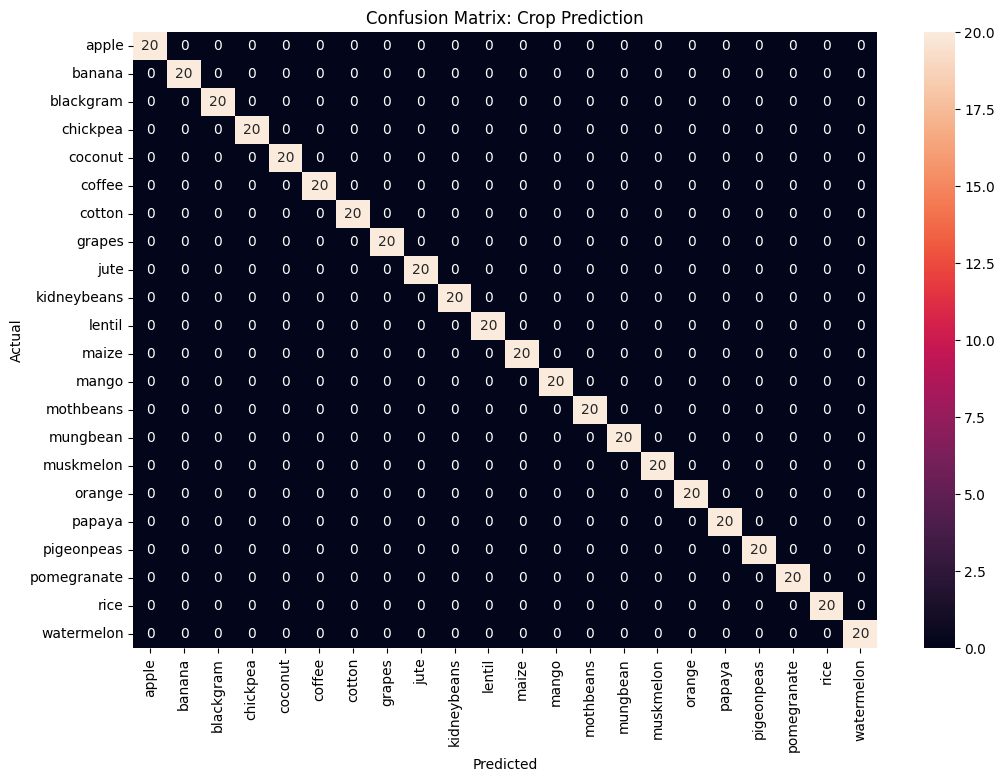

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate detailed metrics for the classification task using the grid search best estimator
best_clf = grid.best_estimator_
# Use X_test_scaled.values to prevent the UserWarning about feature names
y_pred_clf = best_clf.predict(X_test_scaled.values)

print('Classification Report (Random Forest):')
print(classification_report(y_test, y_pred_clf, target_names=encoder.classes_))

# Visualizing Performance: Confusion Matrix
plt.figure(figsize=(12, 8))
cm = confusion_matrix(y_test, y_pred_clf)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.title('Confusion Matrix: Crop Prediction')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 🧪 Task 5: Linear Regression with Multiple Variables
We use multiple independent variables (N, P, K, etc.) to predict a single continuous dependent variable (Rainfall).

In [ ]:
# Using all available features for regression
multi_lr = LinearRegression()
multi_lr.fit(X_tr_sc, y_tr)

# Intercept and Coefficients
print(f'Model Intercept: {multi_lr.intercept_:.4f}')
coeff_df = pd.DataFrame(multi_lr.coef_, X_reg.columns, columns=['Coefficient'])
display(coeff_df.sort_values(by='Coefficient', ascending=False))

# Evaluate predictions on the test set to ensure full completion
y_pred_multi = multi_lr.predict(X_te_sc)
print('\nMultiple Linear Regression Evaluation:')
print(f'R^2 Score: {r2_score(y_te, y_pred_multi):.4f}')
print(f'RMSE:      {np.sqrt(mean_squared_error(y_te, y_pred_multi)):.4f}')
print(f'MAE:       {mean_absolute_error(y_te, y_pred_multi):.4f}')

Model Intercept: 102.6613


,Coefficient
humidity,5.864026
N,2.733493
P,0.916854
temperature,-3.966281
K,-6.754377
ph,-8.417931



Multiple Linear Regression Evaluation:
R^2 Score: 0.0124
RMSE:      54.5257
MAE:       41.2479


## 🤖 Task 6: Logistic Regression for Crop Classification
Logistic Regression is used to classify the 'label' (crop type) based on environmental factors.

In [ ]:
# Initialize and train Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Evaluate
train_acc = log_reg.score(X_train_scaled, y_train)
test_acc = log_reg.score(X_test_scaled, y_test)

print(f'Logistic Regression Training Accuracy: {train_acc:.4f}')
print(f'Logistic Regression Testing Accuracy:  {test_acc:.4f}')

Logistic Regression Training Accuracy: 0.9739
Logistic Regression Testing Accuracy:  0.9727


## ✨ Task 7: Building Python Programs to Use Principal Component Analysis (PCA)
We will use PCA to reduce the dimensionality of our environmental features while retaining most of the variance. We'll also visualize the explained variance ratio.

In [ ]:
from sklearn.decomposition import PCA

# Initialize PCA
pca = PCA(n_components=None) # Keep all components initially to analyze variance
X_train_pca = pca.fit_transform(X_train_scaled)

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Print variance explained by components
for i, (var, cum_var) in enumerate(zip(explained_variance, cumulative_variance)):
    print(f'PC{i+1}: Explained Variance = {var:.4f} | Cumulative Variance = {cum_var:.4f}')

# Apply PCA with 95% variance threshold
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_pca_95 = pca_95.fit_transform(X_train_scaled)
X_test_pca_95 = pca_95.transform(X_test_scaled)

print(f'\nNumber of components selected to retain 95% variance: {pca_95.n_components_}')

PC1: Explained Variance = 0.2738 | Cumulative Variance = 0.2738
PC2: Explained Variance = 0.1867 | Cumulative Variance = 0.4605
PC3: Explained Variance = 0.1531 | Cumulative Variance = 0.6136
PC4: Explained Variance = 0.1461 | Cumulative Variance = 0.7597
PC5: Explained Variance = 0.1144 | Cumulative Variance = 0.8740
PC6: Explained Variance = 0.0984 | Cumulative Variance = 0.9724
PC7: Explained Variance = 0.0276 | Cumulative Variance = 1.0000

Number of components selected to retain 95% variance: 6


## ⚖️ Task 8: Building Python Programs to Use Naïve Bayes Classification
We will implement a Gaussian Naïve Bayes model on our scaled dataset and evaluate its classification performance.

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Initialize and train Gaussian Naive Bayes Classifier
nb_classifier = GaussianNB()
nb_classifier.fit(X_train_scaled, y_train)

# Predict and evaluate
y_pred_nb = nb_classifier.predict(X_test_scaled)
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print(f'Gaussian Naïve Bayes Testing Accuracy: {nb_accuracy:.4f}')

Gaussian Naïve Bayes Testing Accuracy: 0.9955


## 🖥️ Task 9: Building Programs to Use Support Vector Machine (SVM)
We will train a Support Vector Machine (SVM) classifier using a Radial Basis Function (RBF) kernel on the scaled dataset.

In [ ]:
from sklearn.svm import SVC

# Initialize and train SVM Classifier
svm_classifier = SVC(kernel='rbf', C=1.0, random_state=42)
svm_classifier.fit(X_train_scaled, y_train)

# Predict and evaluate
y_pred_svm = svm_classifier.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f'Support Vector Machine (RBF Kernel) Testing Accuracy: {svm_accuracy:.4f}')

Support Vector Machine (RBF Kernel) Testing Accuracy: 0.9841
